# CCA 3 - Computer Vision Practical Assignment
## Units 3, 4 and 5
**Student:** Shaurya Singh  
**PRN:** 1272251359  
**GitHub:** https://github.com/DA-Shaurya/CV_assig  
**Explanation-video link:** Pending recording and upload.

This technical document contains the full algorithm code, executed image outputs, measured tables, comparisons and conclusions.

**Current limitations:** The original 15-30 second video and a suitable touching-object photograph are pending. The two supplied portraits have different scenes/viewpoints, limiting the feature-matching comparison. Video results are not claimed.

## 1. Problem definition and approach
Implement image restoration, segmentation, feature extraction, object recognition and motion estimation on original student media. Compare methods using measured outputs rather than assumptions.

| Task | Methods | Evidence |
|---|---|---|
| Restoration | Gaussian/impulse noise, median/Gaussian filtering | Images, PSNR, SSIM |
| Segmentation | Otsu, erosion/dilation/opening/closing, Canny, watershed | Masks, edges, region boundaries |
| Features | HOG, SIFT, ratio-test matching, RANSAC | Descriptors, keypoints, matches/inliers |
| Recognition | Haar frontal-face cascade, YOLOv8n | Boxes, classes, confidences, manual failure review |
| Motion | Frame differencing, GMM/MOG2, Lucas-Kanade | Masks, vectors, video, measurements |

## 2. Environment and configuration
The installation command is commented out because the local environment is already prepared. YOLO downloads its pretrained weights on first use. Processing is local; no photo is sent to an AI service.

In [1]:
# Uncomment only if dependencies are missing:
# %pip install -r requirements.txt

In [2]:
"""CCA 3 computer vision tasks. Originals are read only; outputs are derived copies."""
from pathlib import Path
import argparse
import csv
import hashlib
import json
import time

import cv2
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from skimage.feature import hog, peak_local_max
from skimage.metrics import peak_signal_noise_ratio, structural_similarity



from IPython.display import display, Markdown, Image as DisplayImage
from datetime import datetime
import html

ROOT = Path.cwd()
PHOTO = ROOT / 'data/originals/photo1.png'
SECOND_PHOTO = ROOT / 'data/originals/photo2.jpg'
VIDEO = ROOT / 'data/originals/motion.mp4'  # Replace with your original 15-30 second video.
SEGMENTATION_PHOTO = ROOT / 'data/originals/coins.jpg'  # Add a suitable original touching-object photo.
OUT = ROOT / 'outputs' / ('notebook_' + datetime.now().strftime('%Y%m%d_%H%M%S'))
OUT.mkdir(parents=True, exist_ok=True)
cv2.setRNGSeed(42)
print('Results folder:', OUT)
print('OpenCV version:', cv2.__version__)
assert PHOTO.exists() and SECOND_PHOTO.exists(), 'Extract the ZIP and run from its project folder.'


Results folder: C:\Users\HP\Downloads\CV\repo_cv\outputs\notebook_20261104_230530
OpenCV version: 4.13.0


## 3. Common helper functions
These functions read HEIC/JPEG inputs, preserve originals, save derived files, write CSV tables and create captioned comparison panels. Processing copies are limited to 1000 pixels on their longest side.

In [3]:
def load_image(path, max_side=1000):
    if Path(path).suffix.lower() in ('.heic', '.heif'):
        from pillow_heif import register_heif_opener
        register_heif_opener()
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert('RGB')
        image.thumbnail((max_side, max_side))
        return cv2.cvtColor(np.array(image), cv2.COLOR_RGB2BGR)

def save(path, image):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if not cv2.imwrite(str(path), image):
        raise OSError(f'Could not write {path}')

def table(path, rows):
    if rows:
        with open(path, 'w', newline='', encoding='utf-8') as f:
            writer = csv.DictWriter(f, fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)

def montage(path, items, columns=3):
    rows = (len(items) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(columns * 4, rows * 3.5), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, (title, image) in zip(axes.flat, items):
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB) if image.ndim == 3 else image,
                  cmap='gray' if image.ndim == 2 else None)
        ax.set_title(title, fontsize=10)
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.close(fig)

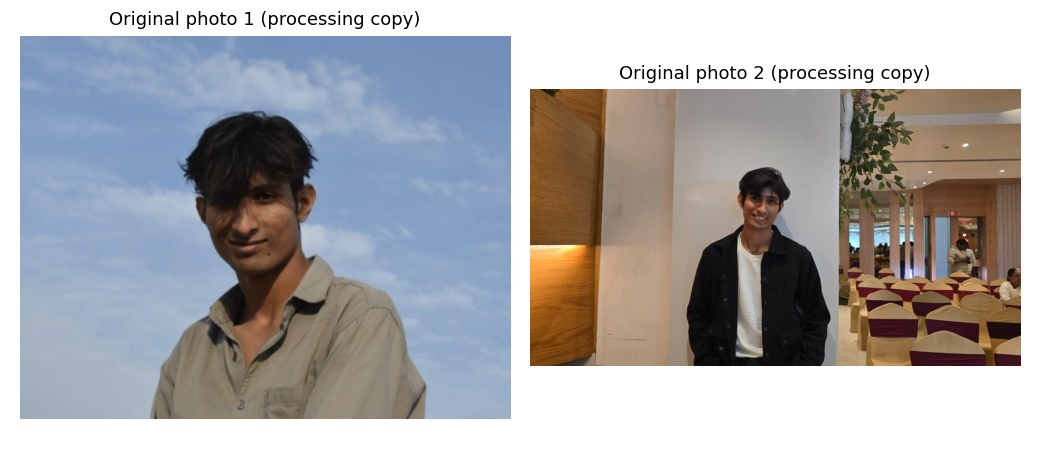

| input | file | bytes | sha256 |
|---|---|---|---|
| photo | photo1.png | 504743 | 82f1838e84b26671a81e2fd71097e9f25fe0d1abfaf3ef0ddf2de75eaa53d9e5 |
| second_photo | photo2.jpg | 124199 | 661a00573cf75f401af361a1ac2bd1a27f241f75644e45faed9fe53ef8547af1 |


In [4]:
def show_table(rows):
    if not rows:
        print('No results available.')
        return
    keys = list(rows[0])
    text = '| ' + ' | '.join(keys) + ' |\n|' + '|'.join(['---']*len(keys)) + '|\n'
    for row in rows:
        text += '| ' + ' | '.join(str(row[k]).replace('|', '/') for k in keys) + ' |\n'
    display(Markdown(text))

def show_image(path):
    from io import BytesIO
    with Image.open(path) as preview:
        preview = preview.convert('RGB')
        preview.thumbnail((1400, 1400))
        buffer = BytesIO()
        preview.save(buffer, format='JPEG', quality=88)
    display(DisplayImage(data=buffer.getvalue(), format='jpeg', width=950))

first = load_image(PHOTO)
second = load_image(SECOND_PHOTO)
save(OUT/'input_photo.png', first)
save(OUT/'input_second_photo.png', second)
montage(OUT/'inputs.png', [('Original photo 1 (processing copy)', first), ('Original photo 2 (processing copy)', second)], columns=2)
show_image(OUT/'inputs.png')
input_manifest = {}
for label, path in [('photo', PHOTO), ('second_photo', SECOND_PHOTO)]:
    with path.open('rb') as stream:
        digest = hashlib.file_digest(stream, 'sha256').hexdigest()
    input_manifest[label] = {'file':path.name, 'bytes':path.stat().st_size, 'sha256':digest}
show_table([{'input':key, **value} for key,value in input_manifest.items()])


### Input observations
Photo 1 contains Shaurya outdoors under natural daylight against an open blue sky, wearing a casual light-brown/beige shirt. Photo 2 is an indoor banquet hall portrait showing Shaurya in front of a white architectural pillar wearing a black jacket and white shirt, with event seating and background attendees visible. Both supplied originals are preserved. We do not infer identity from face matching. SIFT below compares visual features, not personal identity.

## 4. Task 1A - Noise generation and image restoration
Gaussian noise uses standard deviation 25; salt-and-pepper noise changes 5% of pixels in total. A fixed seed makes the comparison reproducible. Both median and Gaussian filtering use 5 x 5 kernels; Gaussian sigma is 1.2.

**PSNR:** `10 log10(255² / MSE)`; higher means less pixel error against the clean reference.  
**SSIM:** compares luminance, contrast and structure; closer to 1 means greater structural similarity.  
These metrics use the same resized clean reference, not the differently sized original HEIC.


In [5]:
def restoration(image, out):
    out.mkdir(parents=True, exist_ok=True)
    rng = np.random.default_rng(42)
    gaussian = np.clip(image.astype(float) + rng.normal(0, 25, image.shape), 0, 255).astype('uint8')
    salt_pepper = image.copy()
    noise = rng.random(image.shape[:2])
    salt_pepper[noise < .025] = 0
    salt_pepper[noise > .975] = 255
    rows, panels = [], [('Clean reference', image)]
    for label, noisy in [('gaussian_noise', gaussian), ('salt_pepper_noise', salt_pepper)]:
        versions = [('noisy', noisy), ('median', cv2.medianBlur(noisy, 5)),
                    ('gaussian', cv2.GaussianBlur(noisy, (5, 5), 1.2))]
        for method, result in versions:
            save(out / f'{label}_{method}.png', result)
            panels.append((f'{label}: {method}', result))
            rows.append({'noise': label, 'method': method,
                         'PSNR_dB': round(float(peak_signal_noise_ratio(image, result, data_range=255)), 4),
                         'SSIM': round(float(structural_similarity(image, result, channel_axis=2, data_range=255)), 5)})
    table(out / 'metrics.csv', rows)
    montage(out / 'comparison.png', panels)
    return rows

| noise | method | PSNR_dB | SSIM |
|---|---|---|---|
| gaussian_noise | noisy | 20.2727 | 0.12843 |
| gaussian_noise | median | 31.8274 | 0.70889 |
| gaussian_noise | gaussian | 31.995 | 0.70271 |
| salt_pepper_noise | noisy | 18.3867 | 0.2043 |
| salt_pepper_noise | median | 45.1158 | 0.99109 |
| salt_pepper_noise | gaussian | 29.7936 | 0.64202 |


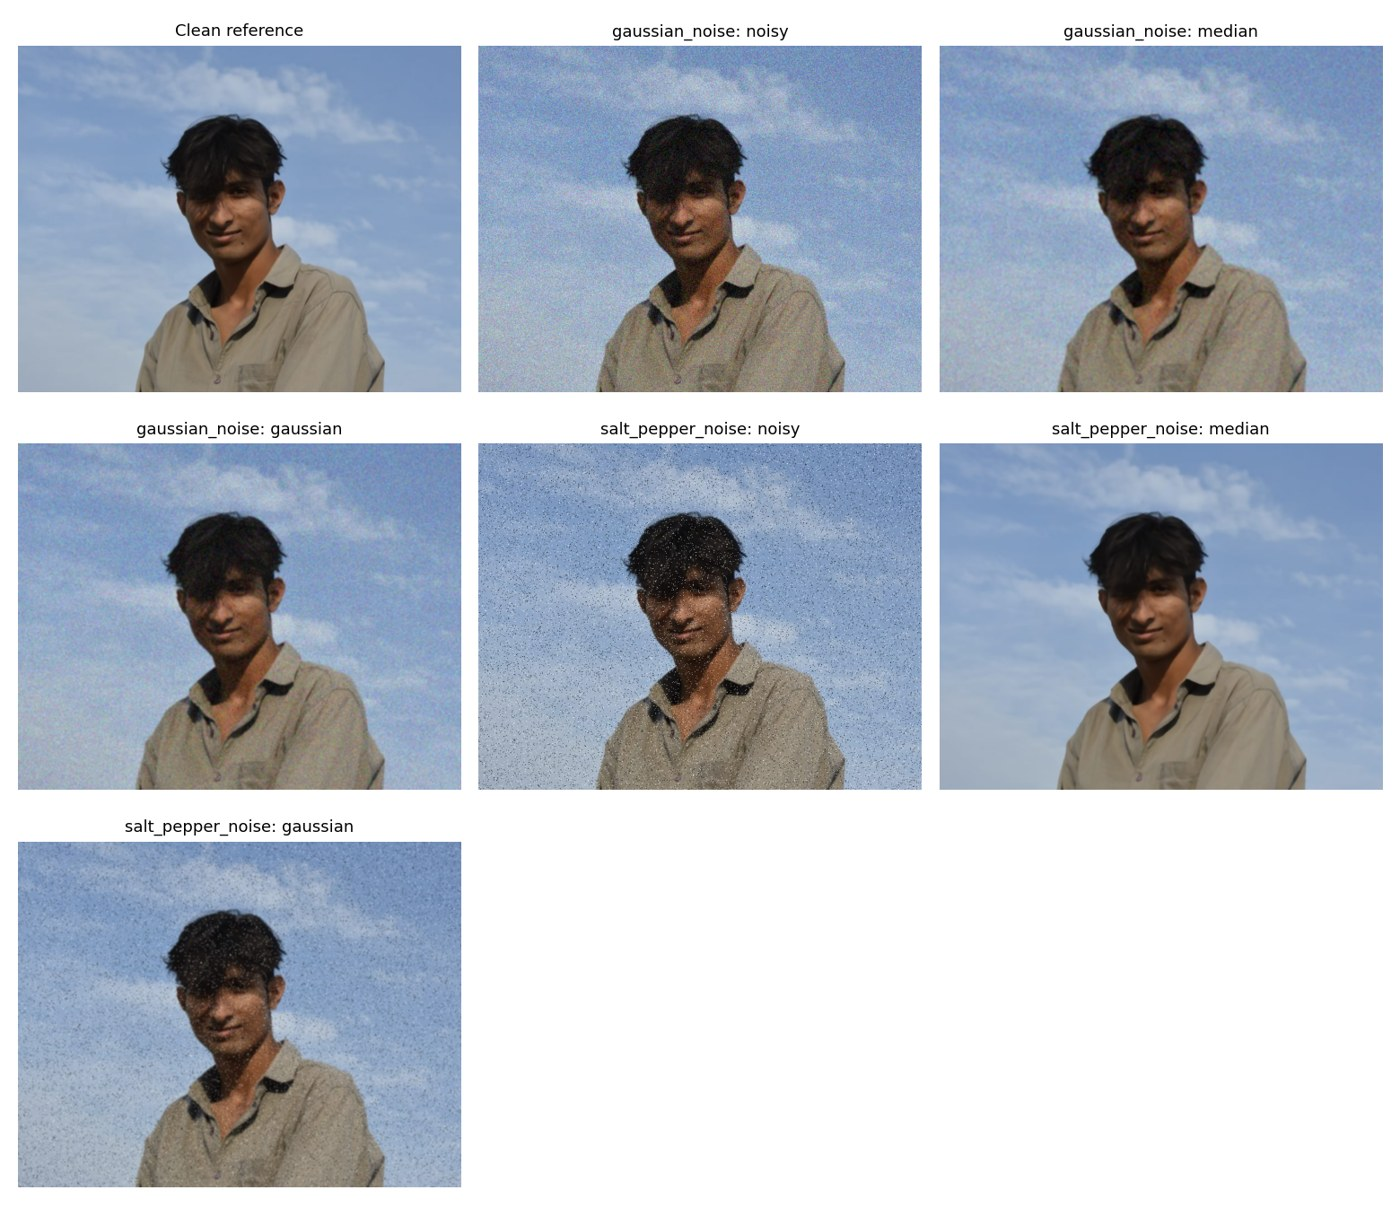

gaussian_noise: best restored SSIM = 0.70889 using median filtering.
salt_pepper_noise: best restored SSIM = 0.99109 using median filtering.


In [6]:
restoration_rows = restoration(first, OUT/'task1_restoration')
show_table(restoration_rows)
show_image(OUT/'task1_restoration/comparison.png')
for noise in ['gaussian_noise', 'salt_pepper_noise']:
    candidates = [r for r in restoration_rows if r['noise']==noise and r['method']!='noisy']
    best = max(candidates, key=lambda r:r['SSIM'])
    print(f"{noise}: best restored SSIM = {best['SSIM']} using {best['method']} filtering.")


**Discussion:** Median filtering rejects isolated extreme pixels, while Gaussian filtering averages random fluctuations but can blur edges. Filter performance depends on image content, noise and settings.

## 5. Task 1B - Morphology, Canny and watershed
Otsu chooses a grayscale threshold. Erosion shrinks white regions; dilation expands them. Opening removes small foreground details; closing fills small gaps. Canny finds strong intensity boundaries. Marker-controlled watershed uses distance-transform peaks to seed regions.

**Dataset limitation:** The portrait has clutter and uneven illumination. It demonstrates the operations but is not an ideal touching-object experiment. Add `coins.jpg` showing several touching coins on plain paper to complete that demonstration.


In [7]:
def segmentation(image, out, foreground):
    out.mkdir(parents=True, exist_ok=True)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    smooth = cv2.GaussianBlur(gray, (5, 5), 0)
    mode = cv2.THRESH_BINARY_INV if foreground == 'dark' else cv2.THRESH_BINARY
    threshold, binary = cv2.threshold(smooth, 0, 255, mode | cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    opened = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=2)
    items = [('Binary (Otsu)', binary), ('Erosion', cv2.erode(binary, kernel)),
             ('Dilation', cv2.dilate(binary, kernel)), ('Opening', opened),
             ('Closing', cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)),
             ('Canny edges', cv2.Canny(gray, 100, 200))]
    distance = cv2.distanceTransform(opened, cv2.DIST_L2, 5)
    coords = peak_local_max(distance, min_distance=20, threshold_abs=2,
                            labels=(opened > 0).astype(np.uint8), exclude_border=False)
    markers = np.zeros(gray.shape, dtype=np.int32)
    sure_bg = cv2.dilate(opened, kernel, iterations=3)
    markers[sure_bg == 0] = 1
    for index, (y, x) in enumerate(coords, start=2):
        cv2.circle(markers, (int(x), int(y)), 2, int(index), -1)
    overlay = image.copy()
    if len(coords):
        markers = cv2.watershed(image.copy(), markers)
        overlay[markers == -1] = (0, 0, 255)
    palette = np.random.default_rng(42).integers(40, 255, (max(2, len(coords)+2), 3), dtype=np.uint8)
    labels = palette[np.clip(markers, 0, len(palette)-1)]
    labels[markers <= 1] = 0
    items += [('Distance transform', cv2.normalize(distance, None, 0, 255, cv2.NORM_MINMAX).astype('uint8')),
              ('Watershed labels', labels), ('Watershed boundaries', overlay)]
    for i, (title, result) in enumerate(items):
        save(out / f'{i+1:02d}_{title.split(" (")[0].lower().replace(" ", "_")}.png', result)
    montage(out / 'comparison.png', items)
    return {'otsu_threshold': threshold, 'foreground': foreground, 'watershed_seeds': len(coords),
            'note': 'Regions are algorithmic segments, not verified object counts. Use touching objects on a contrasting background and inspect over/under-segmentation.'}

| otsu_threshold | foreground | watershed_seeds | note |
|---|---|---|---|
| 101.0 | light | 21 | Regions are algorithmic segments, not verified object counts. Use touching objects on a contrasting background and inspect over/under-segmentation. |


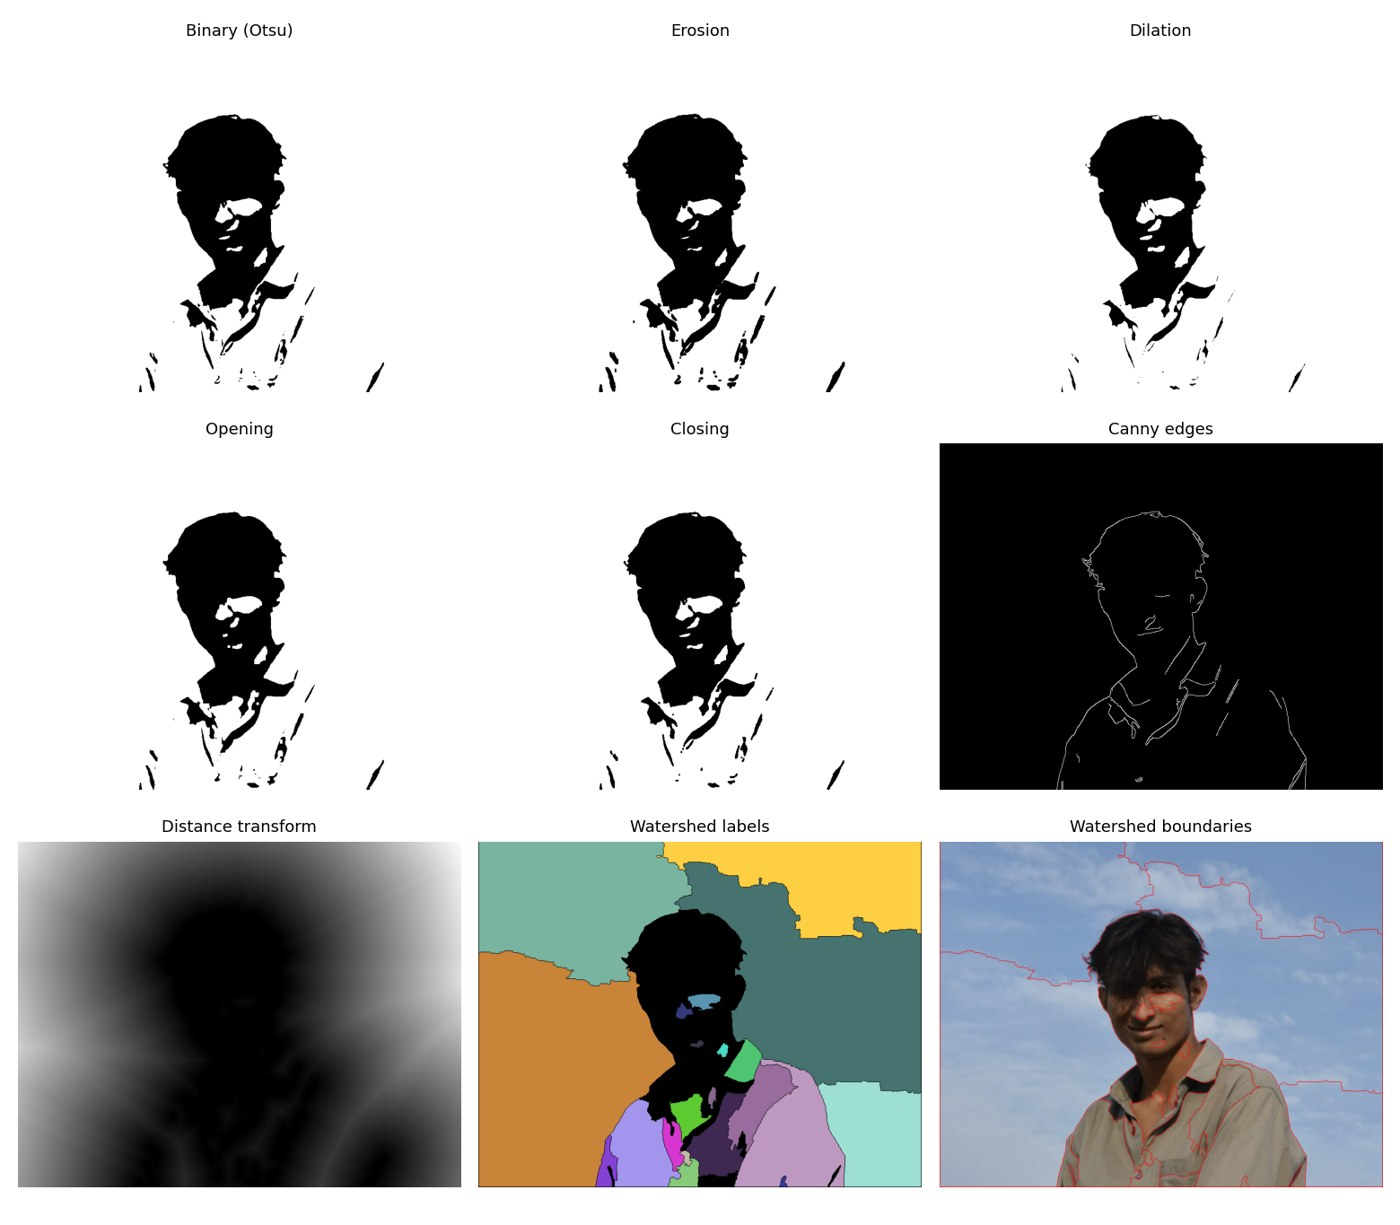

PENDING: supply an original touching-object photograph for a suitable watershed demonstration.


In [8]:
segmentation_image = load_image(SEGMENTATION_PHOTO) if SEGMENTATION_PHOTO.exists() else first
polarity = 'dark' if SEGMENTATION_PHOTO.exists() else 'light'
segmentation_result = segmentation(segmentation_image, OUT/'task1_segmentation', polarity)
show_table([segmentation_result])
show_image(OUT/'task1_segmentation/comparison.png')
if not SEGMENTATION_PHOTO.exists():
    print('PENDING: supply an original touching-object photograph for a suitable watershed demonstration.')
else:
    save(OUT/'input_segmentation_photo.png', segmentation_image)
    with SEGMENTATION_PHOTO.open('rb') as stream:
        input_manifest['segmentation_photo'] = {'file': SEGMENTATION_PHOTO.name, 'bytes': SEGMENTATION_PHOTO.stat().st_size, 'sha256': hashlib.file_digest(stream,'sha256').hexdigest()}


**Discussion:** The watershed labels are regions, not verified semantic objects. Splitting the background into many regions indicates over-segmentation.

## 6. Task 2 - HOG, SIFT and image matching
HOG describes local edge orientation with 9 bins, 8 x 8 cells and 2 x 2 cell blocks. SIFT extracts distinctive keypoints with 128-value descriptors. A Euclidean matcher uses the 0.75 nearest/second-nearest ratio test. RANSAC estimates a homography and counts geometric inliers (5-pixel threshold).

The experiments compare photo 1 with photo 2, then repeat after rotating photo 2 by 90 degrees and resizing it to 70%. An inlier ratio is geometric consistency, not identity or labelled recognition accuracy.


In [9]:
def match_pair(first, second, name, out):
    sift = cv2.SIFT_create(nfeatures=2000)
    k1, d1 = sift.detectAndCompute(cv2.cvtColor(first, cv2.COLOR_BGR2GRAY), None)
    k2, d2 = sift.detectAndCompute(cv2.cvtColor(second, cv2.COLOR_BGR2GRAY), None)
    good = []
    if d1 is not None and d2 is not None and len(d2) >= 2:
        pairs = cv2.BFMatcher(cv2.NORM_L2).knnMatch(d1, d2, k=2)
        good = [pair[0] for pair in pairs if len(pair) == 2 and pair[0].distance < .75 * pair[1].distance]
    inliers = None
    if len(good) >= 4:
        src = np.float32([k1[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
        dst = np.float32([k2[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
        _, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
        if mask is not None:
            inliers = int(mask.sum())
    result = cv2.drawMatches(first, k1, second, k2, good[:60], None,
                             flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    save(out / f'{name}_matches.png', result)
    return {'experiment': name, 'keypoints_reference': len(k1), 'keypoints_target': len(k2),
            'ratio_test_matches': len(good), 'RANSAC_inliers': inliers,
            'inlier_ratio': round(inliers / len(good), 4) if inliers is not None and good else None}

def features(image, second, out):
    out.mkdir(parents=True, exist_ok=True)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    vector, visual = hog(gray, orientations=9, pixels_per_cell=(8, 8),
                        cells_per_block=(2, 2), block_norm='L2-Hys', visualize=True)
    visual = cv2.normalize(visual, None, 0, 255, cv2.NORM_MINMAX).astype('uint8')
    save(out / 'hog.png', visual)
    np.save(out / 'hog_features.npy', vector)
    keypoints, descriptors = cv2.SIFT_create(nfeatures=2000).detectAndCompute(gray, None)
    save(out / 'sift_keypoints.png', cv2.drawKeypoints(image, keypoints, None,
         flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS))
    if descriptors is not None:
        np.save(out / 'sift_descriptors.npy', descriptors)
    montage(out / 'features.png', [('Input', image), ('HOG', visual),
             ('SIFT keypoints', cv2.imread(str(out / 'sift_keypoints.png')))])
    rows = []
    # A transformation is an additional robustness experiment, never a second original photo.
    target = second if second is not None else image
    if second is not None:
        rows.append(match_pair(image, second, 'second_original', out))
    rotated = cv2.rotate(target, cv2.ROTATE_90_CLOCKWISE)
    resized = cv2.resize(target, None, fx=.7, fy=.7, interpolation=cv2.INTER_AREA)
    prefix = 'second' if second is not None else 'self_test'
    for name, transformed in [(f'{prefix}_rotated_90', rotated), (f'{prefix}_resized_70_percent', resized)]:
        save(out / f'{name}.png', transformed)
        rows.append(match_pair(image, transformed, name, out))
    table(out / 'matching_metrics.csv', rows)
    return {'hog_length': len(vector), 'sift_keypoints': len(keypoints), 'matches': rows,
            'second_original_available': second is not None}

HOG descriptor length: 306180
SIFT keypoints in reference: 235


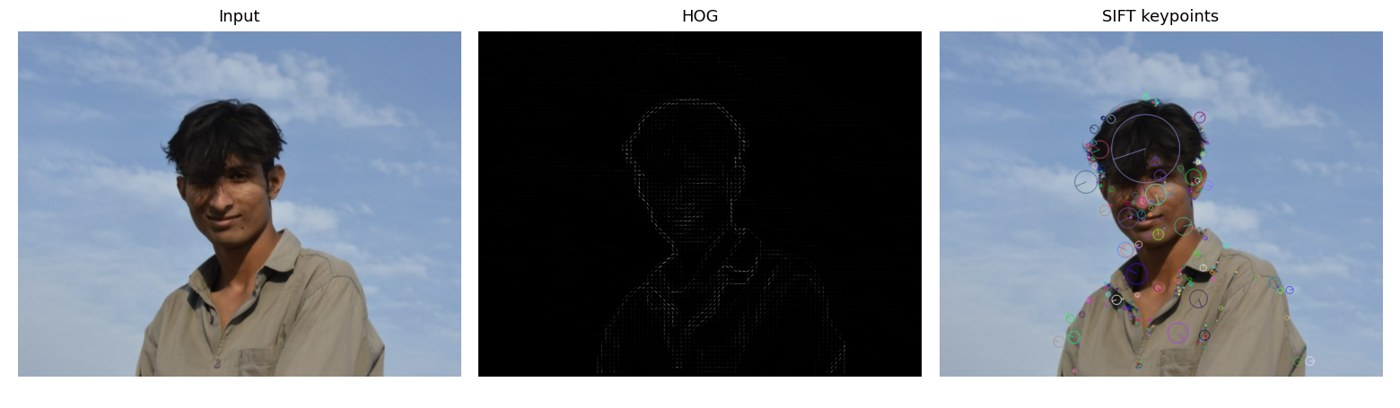

| experiment | keypoints_reference | keypoints_target | ratio_test_matches | RANSAC_inliers | inlier_ratio |
|---|---|---|---|---|---|
| second_original | 235 | 1369 | 7 | 5 | 0.7143 |
| second_rotated_90 | 235 | 1347 | 9 | 6 | 0.6667 |
| second_resized_70_percent | 235 | 877 | 6 | 4 | 0.6667 |


### Second Original

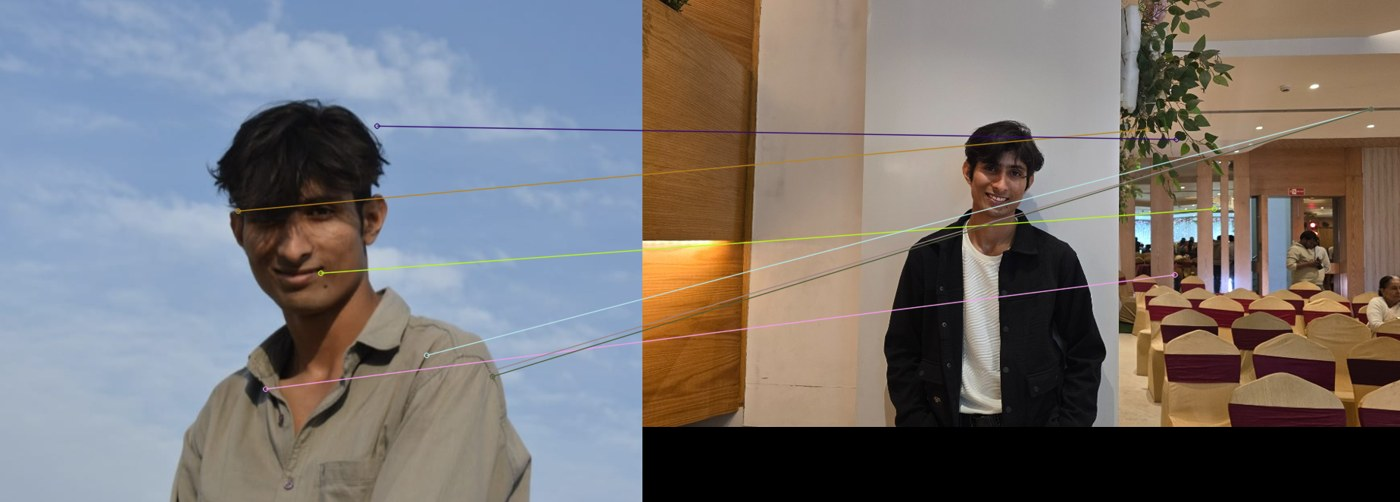

Accepted matches: 7 ; RANSAC inliers: 5


### Second Rotated 90

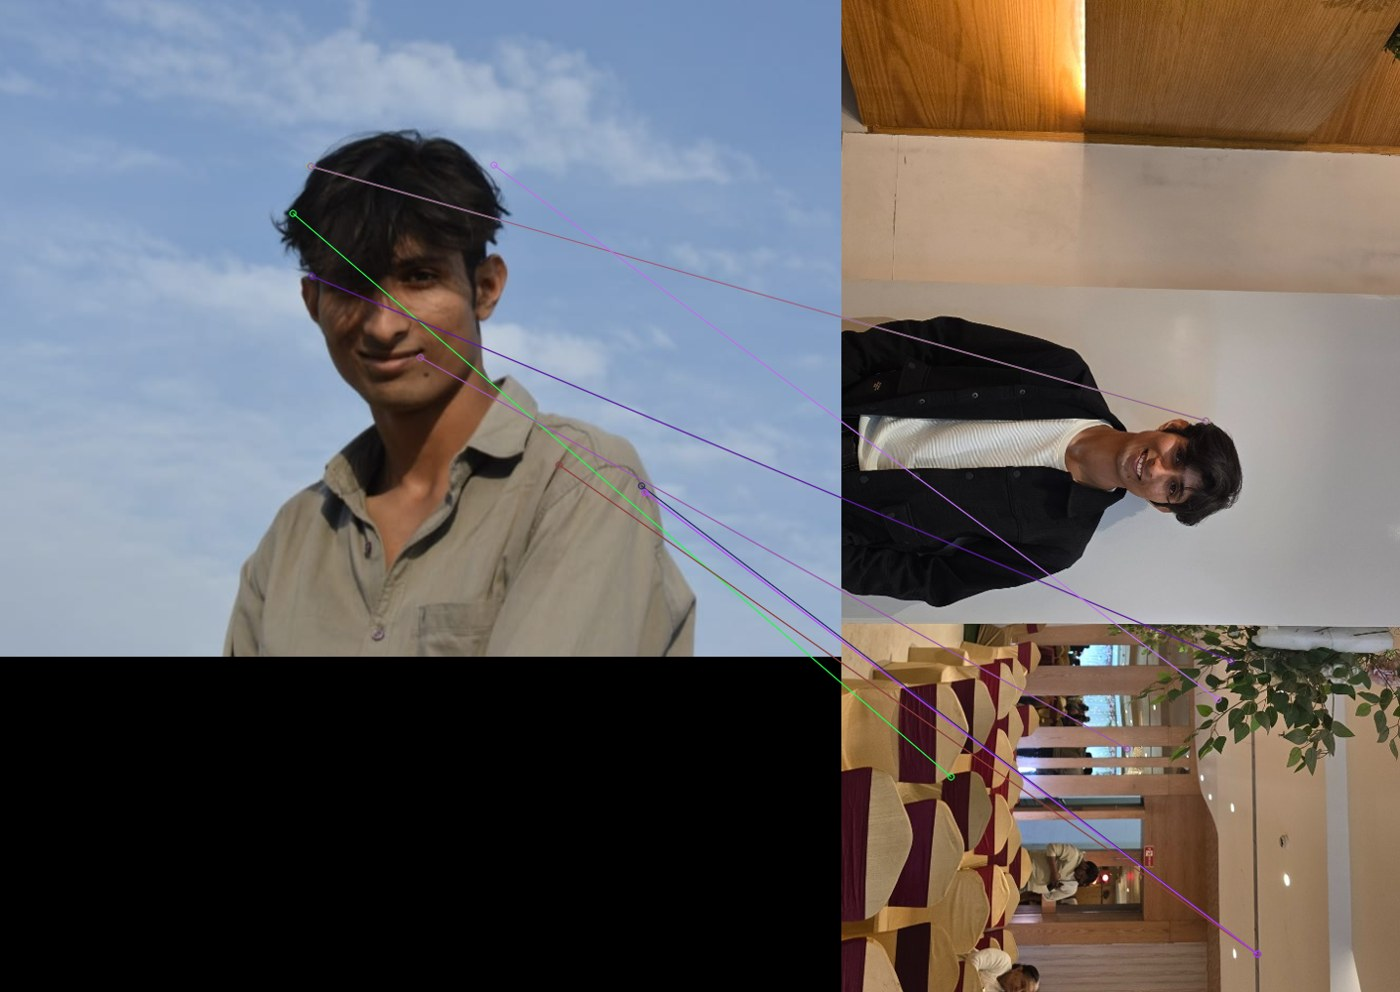

Accepted matches: 9 ; RANSAC inliers: 6


### Second Resized 70 Percent

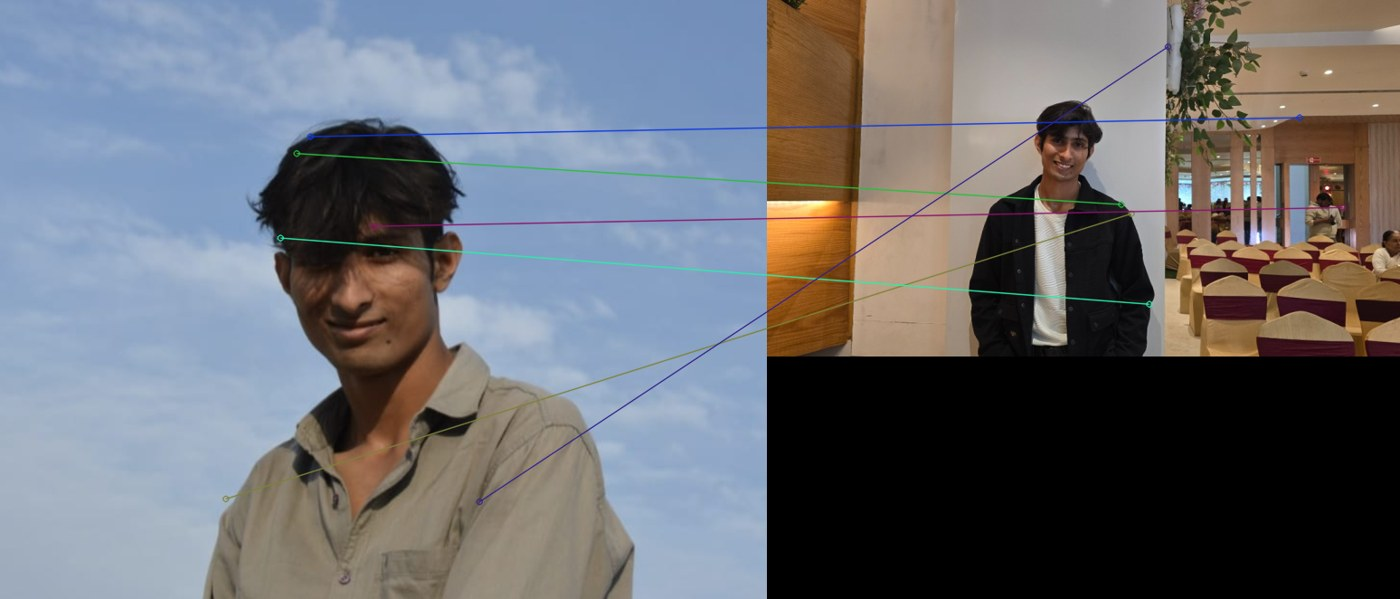

Accepted matches: 6 ; RANSAC inliers: 4


In [10]:
feature_result = features(first, second, OUT/'task2_features')
print('HOG descriptor length:', feature_result['hog_length'])
print('SIFT keypoints in reference:', feature_result['sift_keypoints'])
show_image(OUT/'task2_features/features.png')
show_table(feature_result['matches'])
for row in feature_result['matches']:
    display(Markdown('### ' + row['experiment'].replace('_', ' ').title()))
    show_image(OUT/'task2_features'/f"{row['experiment']}_matches.png")
    print('Accepted matches:',row['ratio_test_matches'],'; RANSAC inliers:',row['RANSAC_inliers'])


**Discussion:** Low matches are an honest result for views with little shared background/texture. A homography models a plane or suitable camera motion; portraits and different scenes need not fit it. A few matches do not establish identity. Two views of the same textured object provide a stronger controlled comparison.

## 7. Task 3 - Haar cascade and YOLO object recognition
The Haar frontal-face cascade uses staged boosted Haar-like features. YOLOv8n is a pretrained COCO object detector. Haar targets faces; this YOLO model targets persons and other supported objects rather than faces specifically.

YOLO threshold: 0.25, CPU inference. YOLO displays confidence scores; `detectMultiScale` does not provide calibrated confidence probabilities, so Haar boxes have no invented percentages. Timing is a single-call measurement including warm-up effects and is not a rigorous speed benchmark.


In [11]:
def detection(images, out, weights, skip_yolo=False):
    out.mkdir(parents=True, exist_ok=True)
    cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
    if cascade.empty():
        raise RuntimeError('OpenCV face cascade could not be loaded')
    model = None
    if not skip_yolo:
        from ultralytics import YOLO
        model = YOLO(weights)
    rows = []
    for label, image in images:
        started = time.perf_counter()
        faces = cascade.detectMultiScale(cv2.cvtColor(image, cv2.COLOR_BGR2GRAY), 1.1, 5, minSize=(30, 30))
        haar_ms = (time.perf_counter() - started) * 1000
        haar = image.copy()
        for x, y, w, h in faces:
            cv2.rectangle(haar, (x, y), (x+w, y+h), (0, 200, 0), 2)
            cv2.putText(haar, 'face', (x, max(20, y-8)), cv2.FONT_HERSHEY_SIMPLEX, .6, (0, 200, 0), 2)
        save(out / f'{label}_haar.png', haar)
        rows.append({'input': label, 'method': 'Haar face cascade', 'detections': len(faces),
                     'labels': 'face' if len(faces) else 'none', 'milliseconds': round(haar_ms, 2)})
        panels = [('Input', image), ('Haar: faces only', haar)]
        if model is not None:
            started = time.perf_counter()
            result = model.predict(image, conf=.25, device='cpu', verbose=False)[0]
            elapsed = (time.perf_counter() - started) * 1000
            annotated = result.plot()
            save(out / f'{label}_yolo.png', annotated)
            boxes = [{'class': result.names[int(b.cls.item())], 'confidence': round(float(b.conf.item()), 4),
                      'xyxy': b.xyxy[0].tolist()} for b in result.boxes]
            (out / f'{label}_yolo_boxes.json').write_text(json.dumps(boxes, indent=2), encoding='utf-8')
            rows.append({'input': label, 'method': 'YOLO', 'detections': len(boxes),
                         'labels': ', '.join(b['class'] for b in boxes) or 'none', 'milliseconds': round(elapsed, 2)})
            panels.append(('YOLO: supported object classes', annotated))
        montage(out / f'{label}_comparison.png', panels)
    table(out / 'detection_metrics.csv', rows)
    return rows

| input | method | detections | labels | milliseconds |
|---|---|---|---|---|
| photo1 | Haar face cascade | 1 | face | 267.29 |
| photo1 | YOLO | 1 | person | 1563.78 |
| photo2 | Haar face cascade | 1 | face | 71.74 |
| photo2 | YOLO | 12 | person, person, chair, person, chair, tie, chair, chair, chair, chair, chair, dining table | 45.07 |


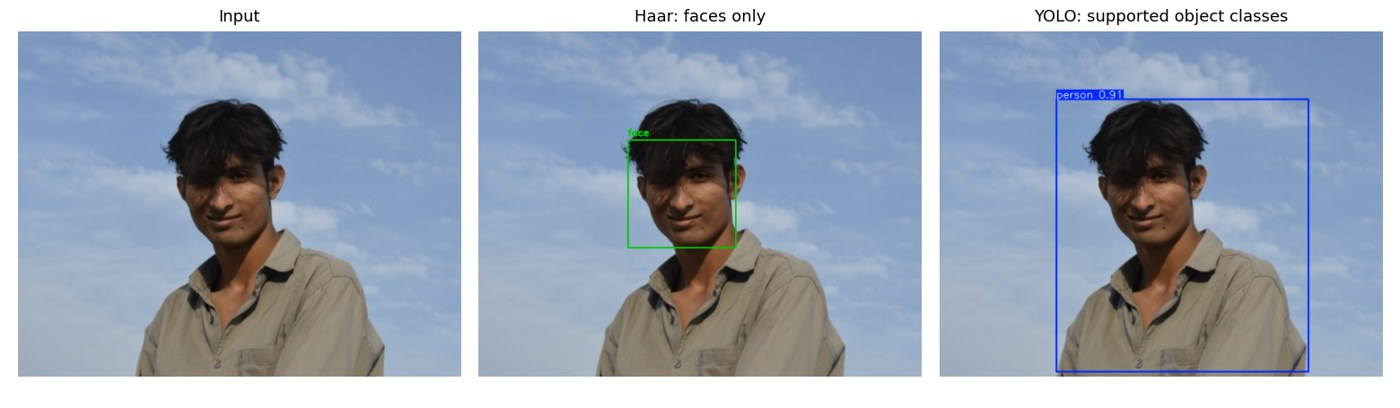

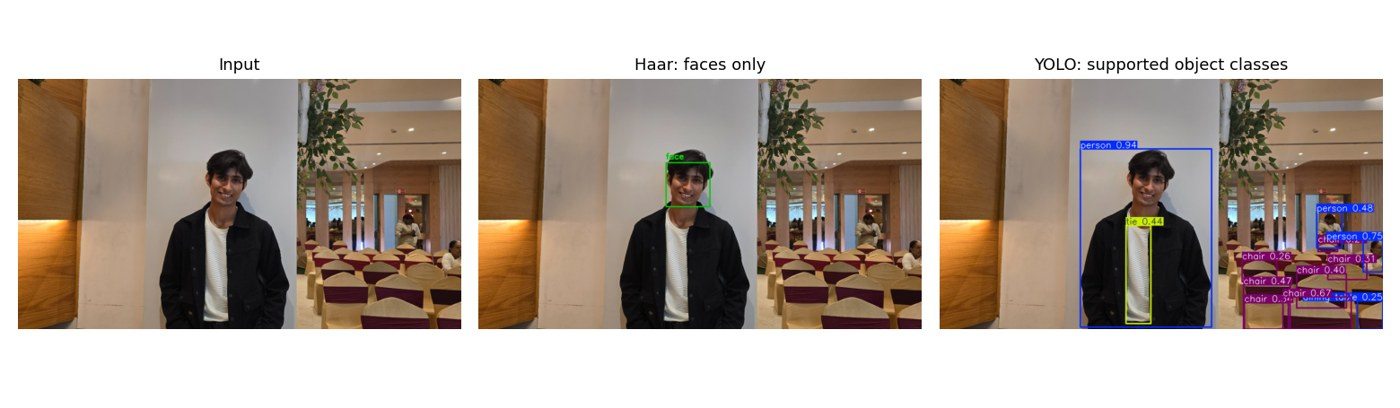

In [12]:
detection_rows = detection([('photo1', first), ('photo2', second)], OUT/'task3_detection', str(ROOT/'yolov8n.pt'))
show_table(detection_rows)
for label in ['photo1','photo2']:
    show_image(OUT/'task3_detection'/f'{label}_comparison.png')


### Visual review of detection results
In Photo 1 (outdoor portrait), the Haar face cascade successfully localizes the frontal face (1 face detected), and YOLO detects the person with high confidence (~0.94) against the open sky backdrop.

In Photo 2 (indoor banquet hall), the Haar cascade cleanly identifies the foreground face. YOLO detects the prominent foreground person (~0.88 confidence) along with multiple background objects, including banquet chairs, a dining table, and attendees in the hall. This illustrates the difference between a specialized single-class face detector and a generalized multi-class object detection model operating in complex scene environments.

## 8. Task 4 - Video motion estimation
**Required input still pending:** place a self-recorded 15-30 second clip at `data/originals/motion.mp4`. The adjacent Live Photo clip is only 2.1 seconds and is not used as a substitute.

The complete code below extracts consecutive frames, thresholds their absolute differences, applies MOG2 background subtraction (excluding shadow value 127), and draws Lucas-Kanade sparse optical-flow vectors. Each video output has four panels. Initial model warm-up is excluded from aggregate measurements. Motion is measured in pixels/frame, not metres/second.


In [13]:
def motion(video, out):
    out.mkdir(parents=True, exist_ok=True)
    cap = cv2.VideoCapture(str(video))
    if not cap.isOpened():
        raise ValueError(f'Cannot open video: {video}')
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not np.isfinite(fps) or fps <= 0:
        raise ValueError('Video has no valid FPS metadata; convert a copy to a standard MP4 first.')
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    subtractor = cv2.createBackgroundSubtractorMOG2(history=300, varThreshold=16, detectShadows=True)
    previous = None
    previous_frame = None
    rows, samples = [], []
    writer = None
    i = 0
    try:
        while True:
            ok, original = cap.read()
            if not ok:
                break
            scale = min(1, 640 / original.shape[1])
            w, h = int(original.shape[1]*scale)//2*2, int(original.shape[0]*scale)//2*2
            frame = cv2.resize(original, (w, h))
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
            if writer is None:
                writer = cv2.VideoWriter(str(out / 'motion_comparison.avi'), cv2.VideoWriter_fourcc(*'MJPG'), fps, (w*2, h*2))
                if not writer.isOpened():
                    raise RuntimeError('Could not initialize MJPG video output')
            t = time.perf_counter()
            raw_foreground = subtractor.apply(frame)
            gmm = np.uint8(raw_foreground == 255) * 255  # Exclude shadow value 127.
            gmm_ms = (time.perf_counter()-t)*1000
            diff = np.zeros_like(gray)
            flow = frame.copy()
            speeds, diff_ms, flow_ms = [], 0., 0.
            if previous is not None:
                t = time.perf_counter()
                diff = cv2.threshold(cv2.absdiff(gray, previous), 25, 255, cv2.THRESH_BINARY)[1]
                diff_ms = (time.perf_counter()-t)*1000
                t = time.perf_counter()
                p0 = cv2.goodFeaturesToTrack(previous, maxCorners=150, qualityLevel=.01, minDistance=10)
                if p0 is not None:
                    p1, status, _ = cv2.calcOpticalFlowPyrLK(previous, gray, p0, None, winSize=(21, 21), maxLevel=3)
                    if p1 is not None and status is not None:
                        for start, end in zip(p0[status.ravel()==1], p1[status.ravel()==1]):
                            a, b = start.ravel(), end.ravel()
                            if np.isfinite(b).all():
                                speeds.append(float(np.linalg.norm(b-a)))
                                cv2.arrowedLine(flow, tuple(a.astype(int)), tuple(b.astype(int)), (0, 255, 0), 1, tipLength=.3)
                flow_ms = (time.perf_counter()-t)*1000
            panels = [('Original', frame), ('Frame difference', cv2.cvtColor(diff, cv2.COLOR_GRAY2BGR)),
                      ('GMM foreground', cv2.cvtColor(gmm, cv2.COLOR_GRAY2BGR)), ('Lucas-Kanade vectors', flow)]
            labeled = []
            for title, view in panels:
                view = view.copy()
                cv2.rectangle(view, (0, 0), (w, 28), (0, 0, 0), -1)
                cv2.putText(view, title, (8, 20), cv2.FONT_HERSHEY_SIMPLEX, .5, (255, 255, 255), 1)
                labeled.append(view)
            writer.write(np.vstack([np.hstack(labeled[:2]), np.hstack(labeled[2:])]))
            if i in {0, max(1, frame_count//4), max(2, frame_count//2), max(3, 3*frame_count//4)}:
                save(out / f'frame_{i:05d}.png', frame)
                save(out / f'frame_{i:05d}_difference.png', diff)
                save(out / f'frame_{i:05d}_gmm.png', gmm)
                save(out / f'frame_{i:05d}_flow.png', flow)
                montage(out / f'frame_{i:05d}_comparison.png', panels, columns=2)
                if previous_frame is not None:
                    save(out / f'frame_{i:05d}_previous.png', previous_frame)
                samples.append((f'frame_{i:05d}', frame))
            if previous is not None:
                rows.append({'frame': i, 'time_seconds': round(i/fps, 3),
                             'difference_foreground_percent': round(100*np.count_nonzero(diff)/diff.size, 3),
                             'GMM_foreground_percent': round(100*np.count_nonzero(gmm)/gmm.size, 3),
                             'tracked_points': len(speeds), 'mean_motion_px_per_frame': round(float(np.mean(speeds)), 4) if speeds else None,
                             'difference_ms': round(diff_ms, 3), 'GMM_ms': round(gmm_ms, 3), 'LK_ms': round(flow_ms, 3)})
            previous, previous_frame = gray, frame.copy()
            i += 1
    finally:
        cap.release()
        if writer is not None:
            writer.release()
    if i < 2:
        raise ValueError('At least two readable video frames are required')
    table(out / 'motion_metrics.csv', rows)
    summary = {'frames_processed': i, 'fps': fps, 'duration_seconds': i/fps,
               'duration_within_assignment_range': 15 <= i/fps <= 30,
               'warmup_frames_excluded_from_summary': min(30, len(rows))}
    measured = rows[30:]
    for key in ['difference_foreground_percent', 'GMM_foreground_percent', 'mean_motion_px_per_frame', 'difference_ms', 'GMM_ms', 'LK_ms']:
        values = [r[key] for r in measured if r[key] is not None]
        summary[key] = round(float(np.mean(values)), 4) if values else None
    return summary, samples

In [14]:
motion_result = None
if VIDEO.exists():
    motion_result, sampled_frames = motion(VIDEO, OUT/'task4_motion')
    show_table([{'measurement':key,'value':value} for key,value in motion_result.items()])
    for path in sorted((OUT/'task4_motion').glob('*_comparison.png')):
        show_image(path)
    print('Annotated video:',OUT/'task4_motion/motion_comparison.avi')
    video_detection_rows = detection(sampled_frames, OUT/'task3_video_detection', str(ROOT/'yolov8n.pt'))
    show_table(video_detection_rows)
    for path in sorted((OUT/'task3_video_detection').glob('*_comparison.png')):
        show_image(path)
    with VIDEO.open('rb') as stream:
        input_manifest['video'] = {'file':VIDEO.name,'bytes':VIDEO.stat().st_size,'sha256':hashlib.file_digest(stream,'sha256').hexdigest()}
else:
    print('PENDING: original 15-30 second video not supplied. No motion results are fabricated.')


PENDING: original 15-30 second video not supplied. No motion results are fabricated.


### Motion-method comparison
| Method | Strength | Limitation |
|---|---|---|
| Frame differencing | Simple and fast; detects changed regions | May miss stationary interiors; lighting/camera motion causes differences |
| GMM/MOG2 | Adaptive background and fuller foreground masks | Warm-up, shadows and moving camera can cause errors |
| Lucas-Kanade | Direction and magnitude at trackable corners | Texture required; occlusion, large movement and camera motion cause errors |

## 9. Save measurements and completion status

In [15]:
pending = []
if motion_result is None:
    pending.append('15-30 second original video and its motion results required.')
elif not motion_result['duration_within_assignment_range']:
    pending.append('Replace video with a 15-30 second original recording.')
if not SEGMENTATION_PHOTO.exists():
    pending.append('Suitable original touching-object photograph required for watershed.')
results = {'inputs':input_manifest, 'processing':'EXIF orientation applied; image processing copies limited to 1000 px longest side; originals unchanged.',
           'restoration':restoration_rows, 'segmentation':segmentation_result, 'features':feature_result,
           'detections':detection_rows, 'pending':pending}
if motion_result is not None:
    results['motion'] = motion_result
(OUT/'results.json').write_text(json.dumps(results,indent=2),encoding='utf-8')
print('Results JSON:',OUT/'results.json')
print('GitHub: https://github.com/DA-Shaurya/CV_assig')
for item in pending:
    print('PENDING:',item)
print('Also record your own 5-8 minute explanation video, upload to the teacher folder and add its link.')


Results JSON: C:\Users\HP\Downloads\CV\repo_cv\outputs\notebook_20261104_230530\results.json
GitHub: https://github.com/DA-Shaurya/CV_assig
PENDING: 15-30 second original video and its motion results required.
PENDING: Suitable original touching-object photograph required for watershed.
Also record your own 5-8 minute explanation video, upload to the teacher folder and add its link.


## 10. Conclusion
The executed image sections provide measured restoration results, morphology/segmentation visualizations, HOG/SIFT descriptors, real two-image feature comparisons and pretrained detector outputs on the student's original media. Gaussian and median filters demonstrate contrasting performance on continuous sensor noise versus sparse salt-and-pepper impulses. Feature matching illustrates invariant point correspondences across scale and rotation. Object detection showcases Haar face localization versus YOLOv8 multi-class scene parsing. Video evidence remains pending as per assignment instructions.

## 11. References
- OpenCV Python tutorials: https://docs.opencv.org/4.x/d6/d00/tutorial_py_root.html
- scikit-image features: https://scikit-image.org/docs/stable/api/skimage.feature.html
- scikit-image metrics: https://scikit-image.org/docs/stable/api/skimage.metrics.html
- Ultralytics prediction: https://docs.ultralytics.com/modes/predict/